In [94]:

import pandas as pd
import numpy as np
#  Load essential data analysis libraries:
# - pandas (pd): for loading, cleaning, and managing tabular survey data
# - numpy (np): for mathematical operations and defining missing values (NaN)


In [95]:
#Load raw dataset 

df_raw = pd.read_csv('../data/raw/WVS_Survey_Trimmed.csv', low_memory=False)


In [96]:
# Define the list of essential variables needed for the analysis
need = ['B_COUNTRY_ALPHA', 'W_WEIGHT', 'Q51', 'Q53', 'Q54', 'Q55']

# Check for missing columns in the raw DataFrame (returns [] if all columns exist)
print([c for c in need if c not in df_raw.columns])   # should print []

[]


In [97]:

# selecting core required variables 
need = ['B_COUNTRY_ALPHA', 'W_WEIGHT', 'Q51', 'Q53', 'Q54', 'Q55']
df = df_raw[need].copy()

# make sure the survey items and weight are numeric
for c in ['W_WEIGHT', 'Q51', 'Q53', 'Q54', 'Q55']:
    df[c] = pd.to_numeric(df[c], errors='coerce')

# WVS missing codes (all negative) -> NaN
items = {'Q51': 'food', 'Q53': 'medicine', 'Q54': 'cash_income', 'Q55': 'shelter'}
for q in items:
    df[q] = df[q].where(df[q] > 0)

# recoding country codes into country names 
country_map = {
    'MMR': 'Myanmar', 'IDN': 'Indonesia', 'MYS': 'Malaysia',
    'PHL': 'Philippines', 'SGP': 'Singapore', 'VNM': 'Vietnam', 'THA': 'Thailand'
}
sea = df[df['B_COUNTRY_ALPHA'].isin(country_map)].copy()

# 1=Often, 2=Sometimes, 3=Rarely, 4=Never -> 4,3,2,1
for q in items:
    sea[q] = 5 - sea[q]

In [98]:
# Generate a summary frequency table for all hardship items (Q51, Q53, Q54, Q55)
# Checks category distribution (1-4) and counts missing values (NaN) per column
print(sea[list(items)].apply(lambda s: s.value_counts(dropna=False).sort_index()))

      Q51   Q53   Q54   Q55
1.0  7690  6808  6182  9611
2.0  1703  2380  2211  1035
3.0  1640  1745  2415   633
4.0   585   677   806   332
NaN     7    15    11    14


In [99]:
# Helper function to compute weighted mean for a column while ignoring missing values
def wmean(g, col):
    # Remove rows where either the variable or survey weight is NaN
    g = g.dropna(subset=[col, 'W_WEIGHT'])
    # Calculate weighted average using NumPy
    return np.average(g[col], weights=g['W_WEIGHT'])

# Calculate weighted average for each hardship item across each SEA country
res = pd.DataFrame({
    name: {c: wmean(g, q) for c, g in sea.groupby('B_COUNTRY_ALPHA')}
    for q, name in items.items()
})

# Rename row indices from 3-letter alpha codes (e.g., 'SGP') to full country names ('Singapore')
res.index = res.index.map(country_map)

# Display final summary table with values rounded to 3 decimal places
res.round(3)

# The higher the score, the higher the economic hardship in the country

,food,medicine,cash_income,shelter
Indonesia,1.886,2.115,1.968,1.308
Myanmar,1.346,1.282,1.882,1.231
Malaysia,1.460,1.617,1.788,1.313
Philippines,1.893,1.990,2.129,1.388
Singapore,1.128,1.155,1.301,1.064
Thailand,1.811,1.780,2.020,1.613
Vietnam,1.214,1.369,1.612,1.068


In [100]:
#calculating the mean deprivation score 
res['deprivation_mean'] = res.mean(axis=1)
res.round(3)

,food,medicine,cash_income,shelter,deprivation_mean
Indonesia,1.886,2.115,1.968,1.308,1.819
Myanmar,1.346,1.282,1.882,1.231,1.435
Malaysia,1.460,1.617,1.788,1.313,1.545
Philippines,1.893,1.990,2.129,1.388,1.850
Singapore,1.128,1.155,1.301,1.064,1.162
Thailand,1.811,1.780,2.020,1.613,1.806
Vietnam,1.214,1.369,1.612,1.068,1.316


In [101]:
#saving the mean deprivation score of each country as a dataframe
deprivation_df = (
    res[['deprivation_mean']]
    .round(3)
    .reset_index()
    .rename(columns={'index': 'country'})
    .sort_values('deprivation_mean', ascending=False)
    .reset_index(drop=True)
)
deprivation_df

,country,deprivation_mean
0,Philippines,1.850
1,Indonesia,1.819
2,Thailand,1.806
3,Malaysia,1.545
4,Myanmar,1.435
5,Vietnam,1.316
6,Singapore,1.162


# Ethical Values and Norms Q177 - 181
Creating column headers for output table based on question numbers.

In [102]:
# Q177-181: justifiability of economic norm violations (1 = Never justifiable, 10 = Always justifiable)
questions = {
    'Q177': 'benefits',         # Claiming government benefits you're not entitled to
    'Q178': 'fare_avoidance',   # Avoiding a fare on public transport
    'Q179': 'stealing',         # Stealing property
    'Q180': 'tax_cheating',     # Cheating on taxes if you have a chance
    'Q181': 'bribery'           # Someone accepting a bribe in the course of their duties
}

Map the abbreviations for the countries to their actual names.

In [103]:
sea_countries = {
    'IDN': 'Indonesia',
    'MMR': 'Myanmar',
    'MYS': 'Malaysia',
    'PHL': 'Philippines',
    'SGP': 'Singapore',
    'THA': 'Thailand',
    'VNM': 'Vietnam'
}


Filtering our dataset file to the 7 Southeast Asian countries above.

In [104]:
df = df_raw[df_raw['B_COUNTRY_ALPHA'].isin(sea_countries.keys())].copy()

Filtering out missing or 'don't know' responses, keeping only valid answers. Then we calculate the weighted average of the responses, using each respondent's survey weight as provided in the dataset (W_WEIGHT) to correct for sampling design.

In [105]:
def weighted_mean(group, col):
    valid = group[group[col] > 0]   # drop negative missing/don't-know codes
    return np.average(valid[col], weights=valid['W_WEIGHT'])

Calculating the weighted mean for each question, separately for each country.

In [106]:
results = {}
for q_col, label in questions.items():
    results[label] = df.groupby('B_COUNTRY_ALPHA').apply(lambda g: weighted_mean(g, q_col))

Lastly, we organise the results into a table.

In [107]:
result_df = pd.DataFrame(results)
result_df.index = result_df.index.map(sea_countries)
result_df = result_df.round(3)
print(result_df)

                 benefits  fare_avoidance  stealing  tax_cheating  bribery
B_COUNTRY_ALPHA                                                           
Indonesia           3.343           2.802     1.583         2.582    1.939
Myanmar             3.655           3.161     1.489         1.622    1.722
Malaysia            4.395           3.979     3.100         3.409    3.085
Philippines         5.211           4.805     3.646         4.041    4.104
Singapore           2.534           1.823     1.351         1.538    1.412
Thailand            2.223           2.231     1.832         1.744    1.774
Vietnam             4.524           3.424     2.495         2.832    2.898


# Personal norms 


Focus on only the columns that are related to Personal norms and calling is 'q_cols'

In [108]:
# Use the Q182-Q195 columns only
q_cols = [f"Q{i}" for i in range(182, 196)]

Data cleaning: removal of missing code and changing variable type to numeric 

In [109]:
#change the variable into numeric and remove missing code
df_sea[q_cols] = df_sea[q_cols].apply(pd.to_numeric, errors="coerce")
df_sea[q_cols] = df_sea[q_cols].where(df_sea[q_cols] > 0)

Printing the mean column for every question for the respective countries 

In [110]:
question_means = df_sea.groupby(country_col)[q_cols].mean()
print(question_means.round(2))

                 Q182  Q183  Q184  Q185  Q186  Q187  Q188  Q189  Q190  Q191  \
B_COUNTRY_ALPHA                                                               
IDN              1.61  1.57  1.58  2.69  1.64  1.48  2.19  1.67  2.44  1.86   
MMR              1.72  1.85  1.41  2.45  1.63  1.36  1.95  1.53  5.04  1.44   
MYS              3.59  3.39  3.52  4.64  3.82  3.15  3.95  3.13  4.47  3.28   
PHL              4.57  3.77  3.02  4.20  4.31  3.13  3.62  3.44  3.96  3.73   
SGP              3.45  2.78  3.29  4.21  4.04  2.46  4.19  1.32  3.36  1.58   
THA              4.21  2.49  2.39  4.58  4.48  2.49  2.76  2.00  2.32  1.90   
VNM              5.64  3.95  4.17  5.23  5.53  4.47  4.88  2.80  4.54  3.05   

                 Q192  Q193  Q194  Q195  
B_COUNTRY_ALPHA                          
IDN              1.73  1.52  1.78  3.38  
MMR              1.55  1.39  1.43  3.93  
MYS              3.10  3.59  3.15  4.58  
PHL              4.18  3.87  3.99  4.13  
SGP              1.30  2.87  1.55  4

# Rebased PV & EV scores OLS for pooled 7 countries

In [111]:
import pandas as pd
import numpy as np

# Start from 'sea' (already has hardship recoded, SEA only)
df_individual = sea.copy()

# Add ethics items (Q177-Q181) from df_raw
ethics_cols = ['Q177', 'Q178', 'Q179', 'Q180', 'Q181']
for col in ethics_cols:
    raw_col = pd.to_numeric(df_raw.loc[df_individual.index, col], errors='coerce')
    df_individual[col] = raw_col.where(raw_col > 0)

# Create individual indices, all rebased to 20
hardship_items = ['Q51', 'Q53', 'Q54', 'Q55']
df_individual['deprivation_mean'] = df_individual[hardship_items].mean(axis=1, skipna=True)   # 1-4
df_individual['deprivation_rebased20'] = df_individual['deprivation_mean'] * 5               # 5-20

EV_raw = df_individual[ethics_cols].mean(axis=1, skipna=True)                                 # 1-10
df_individual['EV_rebased20'] = EV_raw * 2                                                    # 2-20

# Drop missing values
df_model = df_individual.dropna(subset=['deprivation_rebased20', 'EV_rebased20', 'W_WEIGHT'])

print(f"✅ df_model created!")
print(f"   N = {len(df_model)} individuals")
print(f"   Countries: {df_model['B_COUNTRY_ALPHA'].unique()}")

✅ df_model created!
   N = 11601 individuals
   Countries: <StringArray>
['IDN', 'MMR', 'MYS', 'PHL', 'SGP', 'THA', 'VNM']
Length: 7, dtype: str


# OLS Output - Individual Countries

In [112]:

# THIS IS FOR HARDSHIP AND ECONOMIC NORMS (both rebased to 20)
import statsmodels.formula.api as smf

results_by_country = {}

for country in df_model['B_COUNTRY_ALPHA'].unique():
    df_country = df_model[df_model['B_COUNTRY_ALPHA'] == country].copy()

    if len(df_country) < 100:
        print(f"\n{country}: N={len(df_country)} (too small, skipping)")
        continue

    model = smf.ols(
        "EV_rebased20 ~ deprivation_rebased20",
        data=df_country
    ).fit(weights=df_country['W_WEIGHT'])

    results_by_country[country] = model

    print(f"\n{'='*70}")
    print(f"{country} (N={len(df_country)})")
    print('='*70)
    print(model.summary())

with open('../output/tables/country_regressions_economic.txt', 'w') as f:
    for country, model in results_by_country.items():
        f.write(f"{'='*70}\n{country}\n{'='*70}\n")
        f.write(str(model.summary()))
        f.write('\n\n')

print("\nSaved: country_regressions_economic.txt")


IDN (N=3199)
                            OLS Regression Results                            
Dep. Variable:           EV_rebased20   R-squared:                       0.034
Model:                            OLS   Adj. R-squared:                  0.034
Method:                 Least Squares   F-statistic:                     113.7
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           4.09e-26
Time:                        22:10:44   Log-Likelihood:                -8178.2
No. Observations:                3199   AIC:                         1.636e+04
Df Residuals:                    3197   BIC:                         1.637e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept       

In [113]:
q_cols_personal = [f"Q{i}" for i in range(182, 196)]

# bring in the Q182-195 columns from df_raw, matched by respondent
df_model = df_model.join(df_raw.loc[df_model.index, q_cols_personal])

# clean: numeric + drop missing codes
df_model[q_cols_personal] = df_model[q_cols_personal].apply(pd.to_numeric, errors='coerce')
df_model[q_cols_personal] = df_model[q_cols_personal].where(df_model[q_cols_personal] > 0)

# average across the 14 items per respondent (1-10), then rebase to 20 (2-20)
df_model['PV_mean'] = df_model[q_cols_personal].mean(axis=1)
df_model['PV_rebased20'] = df_model['PV_mean'] * 2

print(df_model[['PV_rebased20']].describe())

       PV_rebased20
count  11599.000000
mean       5.763104
std        3.432116
min        2.000000
25%        3.142857
50%        4.714286
75%        7.714286
max       20.000000


In [114]:
results_by_country_personal = {}

print("="*70)
print("INDIVIDUAL-LEVEL OLS: Deprivation -> Personal Norm Violations (both rebased to 20)")
print("="*70)

for country in df_model['B_COUNTRY_ALPHA'].unique():
    df_country = df_model[df_model['B_COUNTRY_ALPHA'] == country].copy()
    if len(df_country) < 100:
        print(f"\n⚠️  {country}: N={len(df_country)} (too small, skipping)")
        continue
    model = smf.ols("PV_rebased20 ~ deprivation_rebased20", data=df_country).fit(weights=df_country['W_WEIGHT'])
    results_by_country_personal[country] = model
    print(f"\n{country} (N={len(df_country)})")
    print(model.summary())

with open('../output/tables/country_regressions_personal.txt', 'w') as f:
    for country, model in results_by_country_personal.items():
        f.write(f"{'='*70}\n{country}\n{'='*70}\n")
        f.write(str(model.summary()))
        f.write('\n\n')

print("\nSaved: country_regressions_personal.txt")

INDIVIDUAL-LEVEL OLS: Deprivation -> Personal Norm Violations (both rebased to 20)

IDN (N=3199)
                            OLS Regression Results                            
Dep. Variable:           PV_rebased20   R-squared:                       0.010
Model:                            OLS   Adj. R-squared:                  0.009
Method:                 Least Squares   F-statistic:                     31.63
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           2.02e-08
Time:                        22:10:44   Log-Likelihood:                -7276.9
No. Observations:                3198   AIC:                         1.456e+04
Df Residuals:                    3196   BIC:                         1.457e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------

In [115]:
# Comparison of OLS (both DVs and the IV rebased to 20, so betas are directly comparable)
term = 'deprivation_rebased20'
comparison_clean = pd.DataFrame({
    country: {
        'Economic Norms: β (coefficient)': results_by_country[country].params[term],
        'Economic Norms: p-value': results_by_country[country].pvalues[term],
        'Economic Norms: Significant?': 'Yes' if results_by_country[country].pvalues[term] < 0.05 else 'No',
        'Personal Norms: β (coefficient)': results_by_country_personal[country].params[term],
        'Personal Norms: p-value': results_by_country_personal[country].pvalues[term],
        'Personal Norms: Significant?': 'Yes' if results_by_country_personal[country].pvalues[term] < 0.05 else 'No',
    }
    for country in results_by_country
}).T

num_cols = ['Economic Norms: β (coefficient)', 'Economic Norms: p-value',
            'Personal Norms: β (coefficient)', 'Personal Norms: p-value']
comparison_clean[num_cols] = comparison_clean[num_cols].astype(float).round(4)

print(comparison_clean)
comparison_clean.to_csv('../output/tables/individual_level_comparison.csv')

     Economic Norms: β (coefficient)  Economic Norms: p-value  \
IDN                           0.1776                   0.0000   
MMR                           0.1193                   0.0000   
MYS                           0.2526                   0.0000   
PHL                           0.0855                   0.0233   
SGP                           0.2634                   0.0000   
THA                           0.1571                   0.0000   
VNM                           0.0282                   0.5266   

    Economic Norms: Significant?  Personal Norms: β (coefficient)  \
IDN                          Yes                           0.0707   
MMR                          Yes                           0.0411   
MYS                          Yes                           0.2139   
PHL                          Yes                           0.0430   
SGP                          Yes                           0.0423   
THA                          Yes                           0.0044

# OLS in graph form

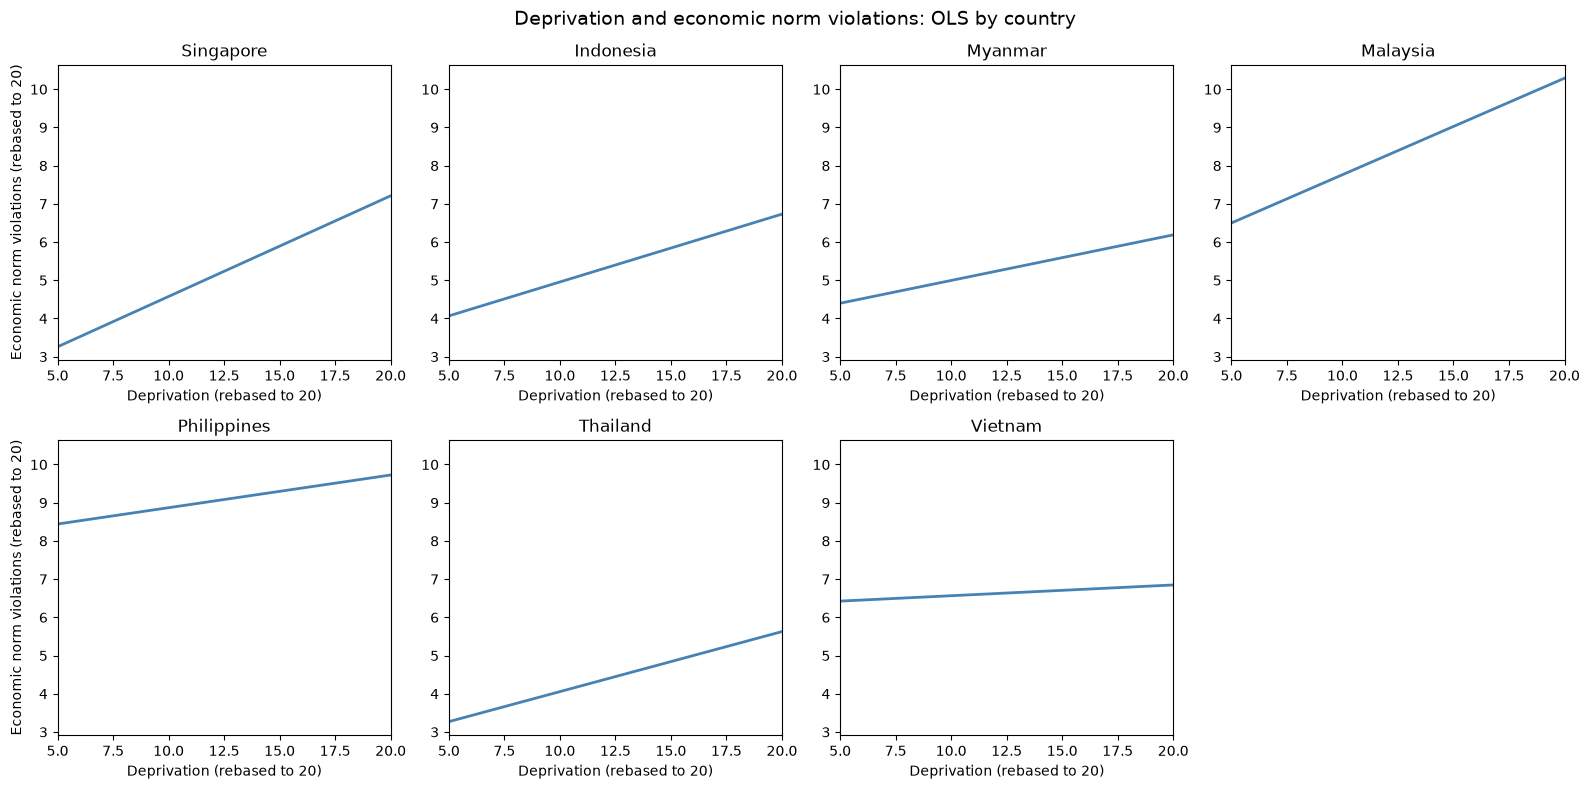

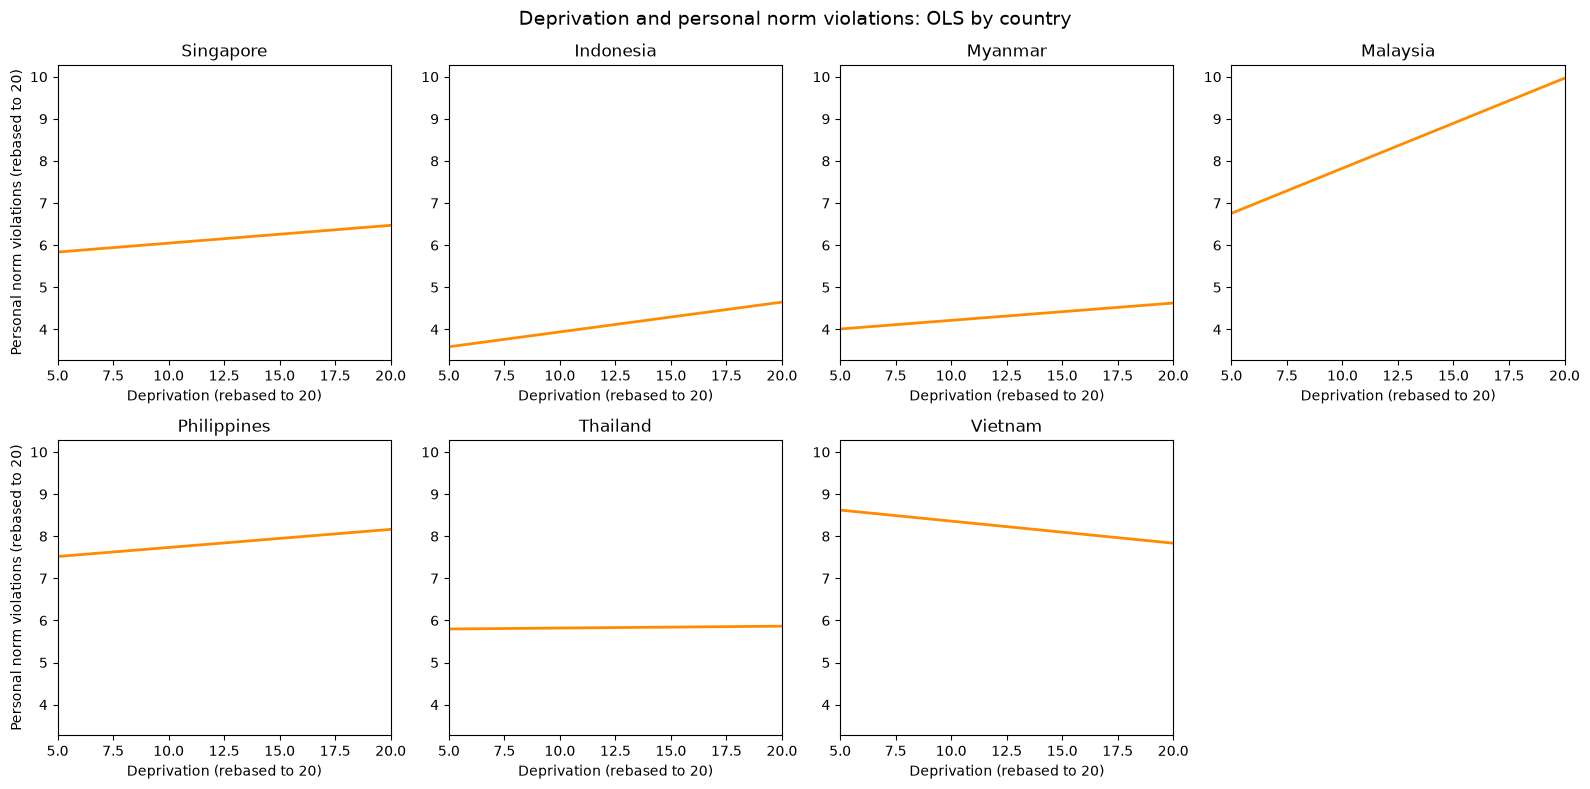

In [116]:
# Same y-axis on every panel so slopes can be compared across countries
# Regression lines for the individual-level country OLS models, one panel per country
# (uses results_by_country and results_by_country_personal, the same models
#  as the saved OLS tables; everything rebased to 20)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

country_names = {
    'IDN': 'Indonesia', 'MMR': 'Myanmar', 'MYS': 'Malaysia',
    'PHL': 'Philippines', 'SGP': 'Singapore', 'THA': 'Thailand', 'VNM': 'Vietnam'
}
order = ['SGP', 'IDN', 'MMR', 'MYS', 'PHL', 'THA', 'VNM']


def plot_country_regressions(results, y_label, color, title, filename):
    x = pd.DataFrame({'deprivation_rebased20': np.linspace(5, 20, 50)})
    fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharey=True)
    axes = axes.ravel()
    for ax, c in zip(axes, order):
        ax.plot(x['deprivation_rebased20'], results[c].predict(x), color=color, linewidth=2)
        ax.set_title(country_names[c])
        ax.set_xlim(5, 20)
        ax.set_xlabel('Deprivation (rebased to 20)')
    axes[-1].axis('off')   # 7 countries, 8 panels
    axes[0].set_ylabel(y_label)
    axes[4].set_ylabel(y_label)
    for ax in axes[:7]:
        ax.tick_params(labelleft=True)   # show y numbers on every panel
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.savefig(f'../output/figures/{filename}', dpi=200, bbox_inches='tight')
    plt.show()


plot_country_regressions(results_by_country, 'Economic norm violations (rebased to 20)', 'steelblue',
                         'Deprivation and economic norm violations: OLS by country',
                         'country_regressions_economic.png')

plot_country_regressions(results_by_country_personal, 'Personal norm violations (rebased to 20)', 'darkorange',
                         'Deprivation and personal norm violations: OLS by country',
                         'country_regressions_personal.png')

# Pooled OLS - All 7 Countries 


In [117]:
import statsmodels.formula.api as smf

model_econ_pooled_simple_rebased = smf.ols(
    "EV_rebased20 ~ deprivation_rebased20",
    data=df_model
).fit(weights=df_model['W_WEIGHT'])
print("=== Economic Norms (Pooled, Rebased 0-20) ===")
print(model_econ_pooled_simple_rebased.summary())

model_pers_pooled_simple_rebased = smf.ols(
    "PV_rebased20 ~ deprivation_rebased20",
    data=df_model
).fit(weights=df_model['W_WEIGHT'])
print("\n=== Personal Norms (Pooled, Rebased 0-20) ===")
print(model_pers_pooled_simple_rebased.summary())

=== Economic Norms (Pooled, Rebased 0-20) ===
                            OLS Regression Results                            
Dep. Variable:           EV_rebased20   R-squared:                       0.034
Model:                            OLS   Adj. R-squared:                  0.034
Method:                 Least Squares   F-statistic:                     407.8
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           3.81e-89
Time:                        22:10:45   Log-Likelihood:                -31090.
No. Observations:               11601   AIC:                         6.218e+04
Df Residuals:                   11599   BIC:                         6.220e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------

# Comparison Graph 

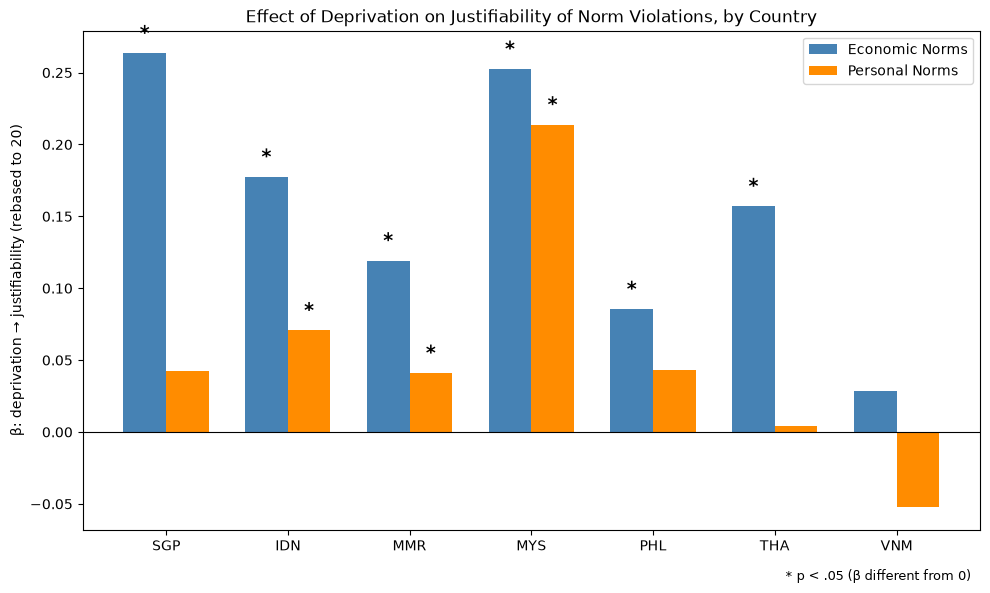

In [118]:
# Bar chart of each country's own beta (not relative to Singapore)
# Uses the per-country rebased models from the "combined OLS table" cell
# (results_by_country_rebased_econ / results_by_country_rebased_pers), so
# economic and personal betas are on the same rebased-to-20 scale and comparable.
import matplotlib.pyplot as plt
import numpy as np

countries = ['SGP', 'IDN', 'MMR', 'MYS', 'PHL', 'THA', 'VNM']
term = 'deprivation_rebased20'


def get_stats(results):
    b = np.array([results[c].params[term] for c in countries])
    p = np.array([results[c].pvalues[term] for c in countries])
    return b, p


econ_b, econ_p = get_stats(results_by_country_rebased_econ)
pers_b, pers_p = get_stats(results_by_country_rebased_pers)

x = np.arange(len(countries))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, econ_b, width, label='Economic Norms', color='steelblue')
bars2 = ax.bar(x + width/2, pers_b, width, label='Personal Norms', color='darkorange')


# * = beta significantly different from zero (p < .05)
def star(bars, b, p):
    for i, bar in enumerate(bars):
        if p[i] < 0.05:
            y = b[i] + 0.01 if b[i] >= 0 else b[i] - 0.02
            ax.text(bar.get_x() + bar.get_width() / 2, y, '*',
                    ha='center', fontsize=14, fontweight='bold')


star(bars1, econ_b, econ_p)
star(bars2, pers_b, pers_p)

ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(countries)
ax.set_ylabel('β: deprivation → justifiability (rebased to 20)')
ax.set_title('Effect of Deprivation on Justifiability of Norm Violations, by Country')
ax.legend()
ax.text(0.99, -0.1, '* p < .05 (β different from 0)',
        transform=ax.transAxes, ha='right', fontsize=9)
plt.tight_layout()

plt.savefig('../output/figures/country_betas_by_norm_type.png', dpi=200, bbox_inches='tight')
plt.show()